In [10]:
import glob, pickle, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['pdf.fonttype'] = 42

In [6]:
Fs = 3e4
out_path = './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/'

files_to_analyze = glob.glob(out_path + '*_EncodingModel.pickle')

In [7]:
files_to_analyze

['./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m11_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m23_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m30_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m29_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m11_unit_3_EncodingModel.pickle']

In [8]:
deg_amp, volt_amp = [], []     # max-magnitude deflection per unit

av_max = []
av_max_bin = []
local_max = []
local_max_bin_pre = []
local_max_bin_post = []
mothID = []

for fp in files_to_analyze:
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    mothID.append(ID)
    print(f'working on {ID}')
    
    fname = os.path.basename(fp)
    with open(fp, 'rb') as f:
        data = pickle.load(f)
        p_spike = np.asarray(data[13]).ravel()    # index 1 = STA
        bins = np.asarray(data[12]).ravel()
        
        derivatives = np.gradient(p_spike, bins)
        max_steepness_idx = np.argmax(derivatives)
        max_steepness = derivatives[max_steepness_idx]
        
        av_max.append(max_steepness)
        av_max_bin.append(bins[max_steepness_idx])
        
        print(f"Max steepness: {max_steepness}")
        print(f"At bin: {bins[max_steepness_idx]}")

        # Also let's check consecutive differences just in case we want the local point-to-point max slope
        dx = np.diff(bins)
        dp = np.diff(p_spike)
        slopes = dp / dx
        max_slope_idx = np.argmax(slopes)
        
        local_max.append(slopes[max_slope_idx])
        local_max_bin_pre = bins[max_slope_idx]
        local_max_bin_post = bins[max_slope_idx+1]
        print(f"Max point-to-point slope: {slopes[max_slope_idx]} between {bins[max_slope_idx]} and {bins[max_slope_idx+1]}")

data = pd.DataFrame({'mothID': mothID, 
                    'av_max': av_max,
                     'av_max_bin': av_max_bin,
                     'local_max': local_max,
                     'local_max_bin_pre': local_max_bin_pre,
                     'local_max_bin_post': local_max_bin_post
                    })

working on m31_unit_3
Max steepness: 0.0005250555708918114
At bin: 0.7940463819294932
Max point-to-point slope: 0.0006062672085358 between 0.7940463819294932 and 1.2387471298457964
working on m31_unit_2
Max steepness: 0.0034697575979447484
At bin: 2.3449674194846146
Max point-to-point slope: 0.0034697575979447484 between 1.9031322995363595 and 2.3449674194846146
working on m31_unit_1
Max steepness: 0.002202641699680095
At bin: 0.4213758364449376
Max point-to-point slope: 0.002745019199781465 between -0.027104356521052253 and 0.4213758364449376
working on m11_unit_2
Max steepness: 0.0022182257215923565
At bin: 1.8291205508587556
Max point-to-point slope: 0.0028609107379395206 between 1.3933546511826869 and 1.8291205508587556
working on m23_unit_1
Max steepness: 0.004806102732956572
At bin: 0.8613617167068224
Max point-to-point slope: 0.0063264994112889866 between 0.8613617167068224 and 1.350625122262107
working on m30_unit_1
Max steepness: 0.002640952233238952
At bin: 1.7297635207881399

In [9]:
data

,mothID,av_max,av_max_bin,local_max,local_max_bin_pre,local_max_bin_post
0,m31_unit_3,0.000525,0.794046,0.000606,2.016083,2.482124
1,m31_unit_2,0.003470,2.344967,0.003470,2.016083,2.482124
2,m31_unit_1,0.002203,0.421376,0.002745,2.016083,2.482124
3,m11_unit_2,0.002218,1.829121,0.002861,2.016083,2.482124
4,m23_unit_1,0.004806,0.861362,0.006326,2.016083,2.482124
5,m30_unit_1,0.002641,1.729764,0.003400,2.016083,2.482124
6,m29_unit_1,0.005568,2.212011,0.005568,2.016083,2.482124
7,m11_unit_3,0.001243,2.482124,0.001243,2.016083,2.482124


{'whiskers': [<matplotlib.lines.Line2D at 0x2e1299f3680>,
 'caps': [<matplotlib.lines.Line2D at 0x2e1299f3c50>,
 'boxes': [<matplotlib.lines.Line2D at 0x2e1299f3380>],
 'medians': [<matplotlib.lines.Line2D at 0x2e129a2c2c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2e129a2c5f0>],
 'means': []}

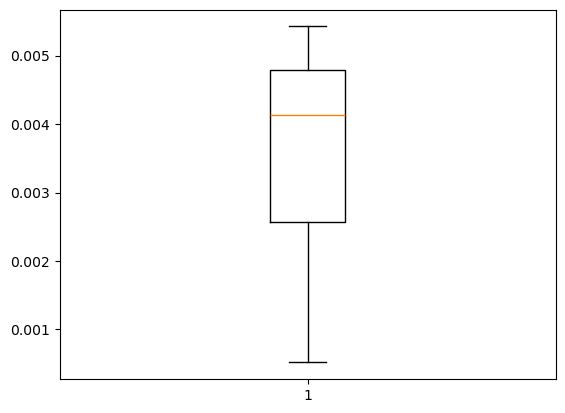

In [6]:
import matplotlib.pyplot as plt

plt.boxplot(data['local_max'])

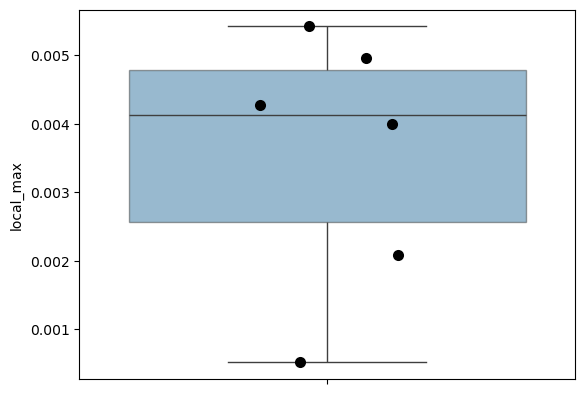

In [8]:
import seaborn as sns

# 1. Create the box plot (hide default outlier fliers)
sns.boxplot(data=data, y="local_max", boxprops=dict(alpha=0.5))

# 2. Overlay the individual data points
sns.stripplot(data=data, y="local_max", color="black", size=8, jitter=0.2)

# Show the visualization
plt.show()

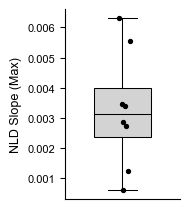

median max NLD slope: 0.00313
mean max NLD slope: 0.00328


In [12]:
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(2.0, 2.2))

values = data['local_max'].values

ax.boxplot(values,
           widths=0.5,
           patch_artist=True,
           showfliers=False,
           boxprops=dict(facecolor='lightgrey', edgecolor='black', linewidth=0.75),
           medianprops=dict(color='black', linewidth=0.75),
           whiskerprops=dict(color='black', linewidth=0.75),
           capprops=dict(color='black', linewidth=0.75))

x_jit = 1 + rng.normal(0, 0.05, size=len(values))
ax.scatter(x_jit, values, s=8, edgecolor='black', facecolor='black', zorder=3)

ax.set_ylabel('NLD Slope (Max)', fontsize=9)
ax.set_xticks([])
ax.tick_params(labelsize=8, width=0.75)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig_out = './dataFolder/Figures/6c_NLDCurvature/selectedUnits/'
os.makedirs(fig_out, exist_ok=True)
plt.tight_layout()
fig.savefig(fig_out + 'nld_curvature_boxplot.pdf', bbox_inches='tight')
plt.show()

print(f'median max NLD slope: {data["local_max"].median():.5f}')
print(f'mean max NLD slope: {data["local_max"].mean():.5f}')